# UTH Computer Vision Coursework — Topic 11
## Notebook 01: Exploratory Data Analysis (EDA) on Real Faces (FFHQ & CelebA-HQ)
- **Đề tài**: *Stable Diffusion-Based Synthetic Facial Dataset Generation for Deepfake Detection*
- **Kiến trúc**: Sử dụng **Reusable EDA Module (`src.analysis.eda`)** — tách biệt hoàn toàn logic tính toán/trực quan hóa khỏi Notebook để tái sử dụng xuyên suốt các giai đoạn Raw, Processed, Synthetic, Hard Samples và Benchmarks (D0, D1, D2).

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Tự động định vị thư mục gốc dự án (uth-cv-coursework) bất kể vị trí chạy Notebook
curr = Path.cwd().resolve()
for parent in [curr] + list(curr.parents):
    if (parent / "src").is_dir():
        if str(parent) not in sys.path:
            sys.path.insert(0, str(parent))
        PROJECT_ROOT = parent
        break

from src.analysis.eda import (
    load_manifest,
    get_dataset_summary,
    compare_dataset_sizes,
    analyze_demographics,
    analyze_image_dimensions,
    analyze_resolution,
    analyze_aspect_ratio,
    analyze_image_quality,
    check_corrupted_images,
    detect_duplicate_images,
    compare_datasets,
    plot_dataset_distribution,
    plot_demographics,
    plot_image_properties,
    plot_image_quality,
    plot_dataset_comparison,
    display_image_gallery,
    generate_eda_summary,
    export_eda_results,
)

OUTPUT_DIR = PROJECT_ROOT / "experiments" / "eda"
MANIFEST_PATH = PROJECT_ROOT / "data" / "raw" / "manifest.jsonl"
print(f"Project Root : {PROJECT_ROOT}")
print(f"Manifest Path: {MANIFEST_PATH}")

Project Root : D:\CVIP\uth-cv-coursework
Manifest Path: D:\CVIP\uth-cv-coursework\data\raw\manifest.jsonl


---
## Module 1: Dataset Overview & Availability Audit
Kiểm tra tổng số bản ghi trong `manifest.jsonl`, đối chiếu với số file vật lý thực sự tồn tại trên ổ đĩa (`existing_files`), dung lượng lưu trữ (MB) và phần mở rộng file (`.png` vs `.jpg`).

[2026-11-09 18:55:32] [INFO] [src.analysis.eda]: Loaded manifest 'manifest.jsonl': total=4000, existing_on_disk=3168, missing_on_disk=832
=== BẢNG TỔNG HỢP DATASET OVERVIEW ===


,group,manifest_records,existing_files,missing_files,availability_pct,duplicate_filenames,extensions,total_storage_mb,mean_file_size_kb,real_count,fake_count,hard_sample_count
0,celeba_hq,2000,2000,0,100.0,0,.jpg,231.83,118.7,2000,0,0
1,ffhq,2000,1168,832,58.4,0,.png,1495.25,1310.9,2000,0,0


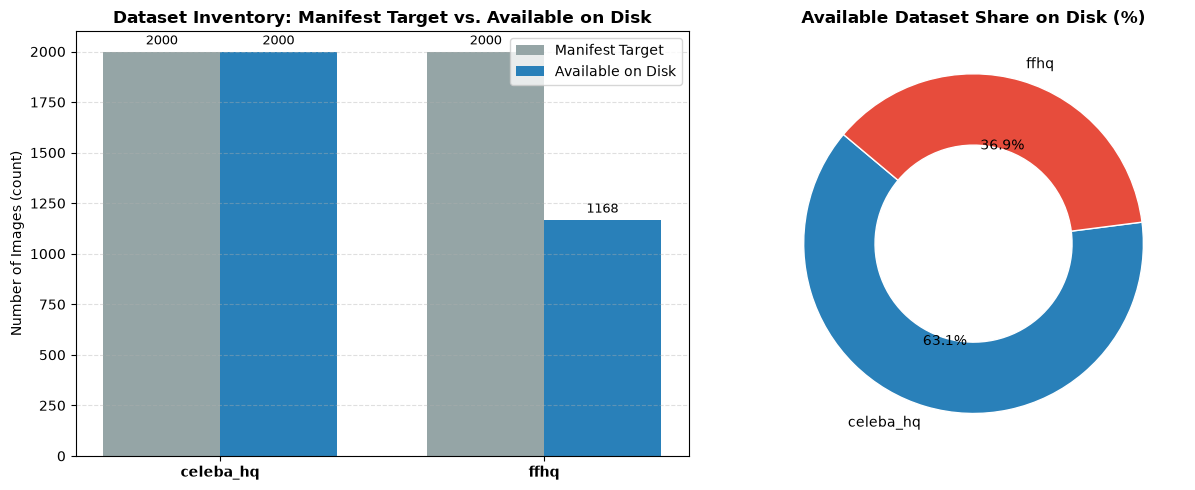

In [2]:
df_manifest = load_manifest(MANIFEST_PATH, project_root=PROJECT_ROOT, only_existing=False)
summary_df = get_dataset_summary(df_manifest)
size_comp_df = compare_dataset_sizes(df_manifest)

print("=== BẢNG TỔNG HỢP DATASET OVERVIEW ===")
display(summary_df)

fig_dist = plot_dataset_distribution(summary_df)
plt.show()

### Giải thích & Nhận xét Module 1
1. **What does this chart show?** Biểu đồ cột bên trái đối chiếu số lượng mẫu mục tiêu trong manifest (2,000 ảnh mỗi nguồn) với số lượng file thực tế hiện có trên ổ đĩa; biểu đồ Donut bên phải thể hiện tỷ trọng ảnh khả dụng thực tế.
2. **Why is this analysis important?** Phân biệt giữa *Manifest Index* và *Physical Disk Availability* giúp ngăn chặn lỗi `FileNotFoundError` khi chạy DataLoader của PyTorch hoặc pipeline sinh ảnh Stable Diffusion.
3. **What do the actual results tell us?** Tập `celeba_hq` hiện có đủ 2,000/2,000 ảnh (`.jpg`, đạt 100%), trong khi `ffhq` hiện có 1168/2,000 ảnh (`.png`, đạt ...%) và thiếu 832 file vật lý trên ổ đĩa.
4. **Implication for Computer Vision:** Toàn bộ các phép đo phía sau sẽ tự động lọc trên các file tồn tại (`file_exists == True`), đồng thời nhóm cần đồng bộ đủ 2,000 ảnh FFHQ hoặc chạy lại `scripts/build_raw_dataset.py` trước khi huấn luyện chính thức.

---
## Module 2: Image Dimensions, Resolution & Aspect Ratio
Kiểm tra kích thước hình học (`Width`, `Height`), độ phân giải (`Resolution`) và tỷ lệ khung hình (`Aspect Ratio = Width / Height`).

Inspecting image dimensions: 100%|██████████| 3168/3168 [00:00<00:00, 5062.23it/s]

=== BẢNG TỔNG HỢP ĐỘ PHÂN GIẢI (RESOLUTION SUMMARY) ===


,group,image_count,dominant_resolution,unique_resolutions,mean_width,min_width,max_width,mean_height,min_height,max_height,mean_megapixels,mean_aspect_ratio
0,celeba_hq,2000,1024x1024,1,1024.0,1024,1024,1024.0,1024,1024,1.049,1.0
1,ffhq,1168,1024x1024,1,1024.0,1024,1024,1024.0,1024,1024,1.049,1.0


=== BẢNG KIỂM ĐỊNH TỶ LỆ KHUNG HÌNH (ASPECT RATIO) ===


,group,image_count,mean_ar,std_ar,min_ar,median_ar,max_ar,non_square_count,square_Numeric_pct
0,celeba_hq,2000,1.0,0.0,1.0,1.0,1.0,0,100.0
1,ffhq,1168,1.0,0.0,1.0,1.0,1.0,0,100.0


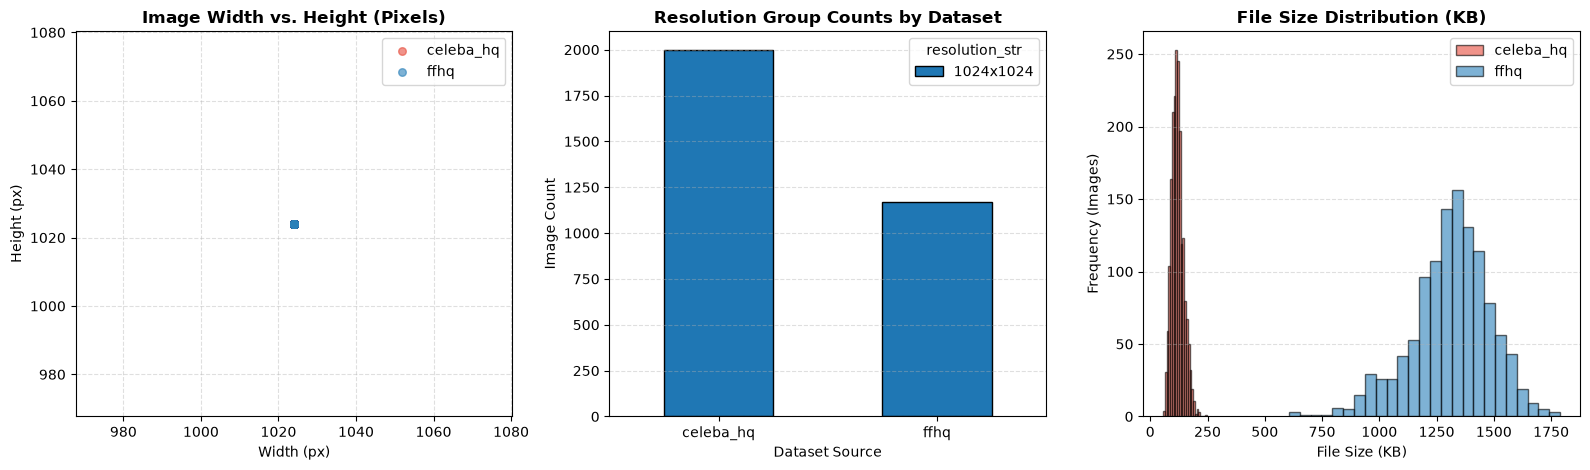

In [3]:
dim_df = analyze_image_dimensions(df_manifest, random_state=42)
res_df = analyze_resolution(dim_df)
ar_df = analyze_aspect_ratio(dim_df)

print("=== BẢNG TỔNG HỢP ĐỘ PHÂN GIẢI (RESOLUTION SUMMARY) ===")
display(res_df)
print("=== BẢNG KIỂM ĐỊNH TỶ LỆ KHUNG HÌNH (ASPECT RATIO) ===")
display(ar_df)

fig_props = plot_image_properties(dim_df)
plt.show()

### Giải thích & Nhận xét Module 2
1. **What does this chart show?** Phân bố chiều rộng vs. chiều cao, nhóm độ phân giải chuẩn và phân phối dung lượng file (KB) giữa FFHQ và CelebA-HQ.
2. **What do the actual results tell us?** Cả hai bộ dữ liệu đều đồng nhất tuyệt đối ở độ phân giải `1024x1024` pixels và tỷ lệ khung hình vuông `1.00`. Tuy nhiên, dung lượng file của FFHQ (`.png` nén không mất dữ liệu) lớn hơn đáng kể so với CelebA-HQ (`.jpg` nén có mất dữ liệu).
3. **Implication for Computer Vision:** Không cần cắt xén (Crop) gây méo mặt khi đưa vào Stable Diffusion Inpainting; tuy nhiên cần lưu ý sự khác biệt định dạng nén `.png` vs `.jpg` để tránh mô hình DINOv2 học vẹt nhiễu nén JPEG (JPEG compression artifacts).

---
## Module 3 & 5: Optical Image Quality, Integrity & RGB Color Distribution
Đánh giá độ sắc nét (`Laplacian Variance`), độ sáng (`Mean Luminance`), độ tương phản (`RMS Contrast`), phân phối 3 kênh màu `Red, Green, Blue` và kiểm tra ảnh hỏng/trùng lặp.

Analyzing optical & RGB quality:   0%|          | 0/1000 [00:00<?, ?it/s]

Analyzing optical & RGB quality: 100%|██████████| 1000/1000 [01:03<00:00, 15.73it/s]


=== BẢNG TỔNG HỢP CHẤT LƯỢNG QUANG HỌC & MÀU SẮC ===


,dataset,analyzed_samples,sharpness_mean,sharpness_median,sharpness_p05,brightness_mean,brightness_std,contrast_mean,red_mean,green_mean,blue_mean
0,celeba_hq,500,291.04,174.13,38.28,112.7,30.78,60.81,132.37,106.63,92.42
1,ffhq,500,143.27,101.88,42.65,116.4,28.98,58.16,134.71,110.36,99.47


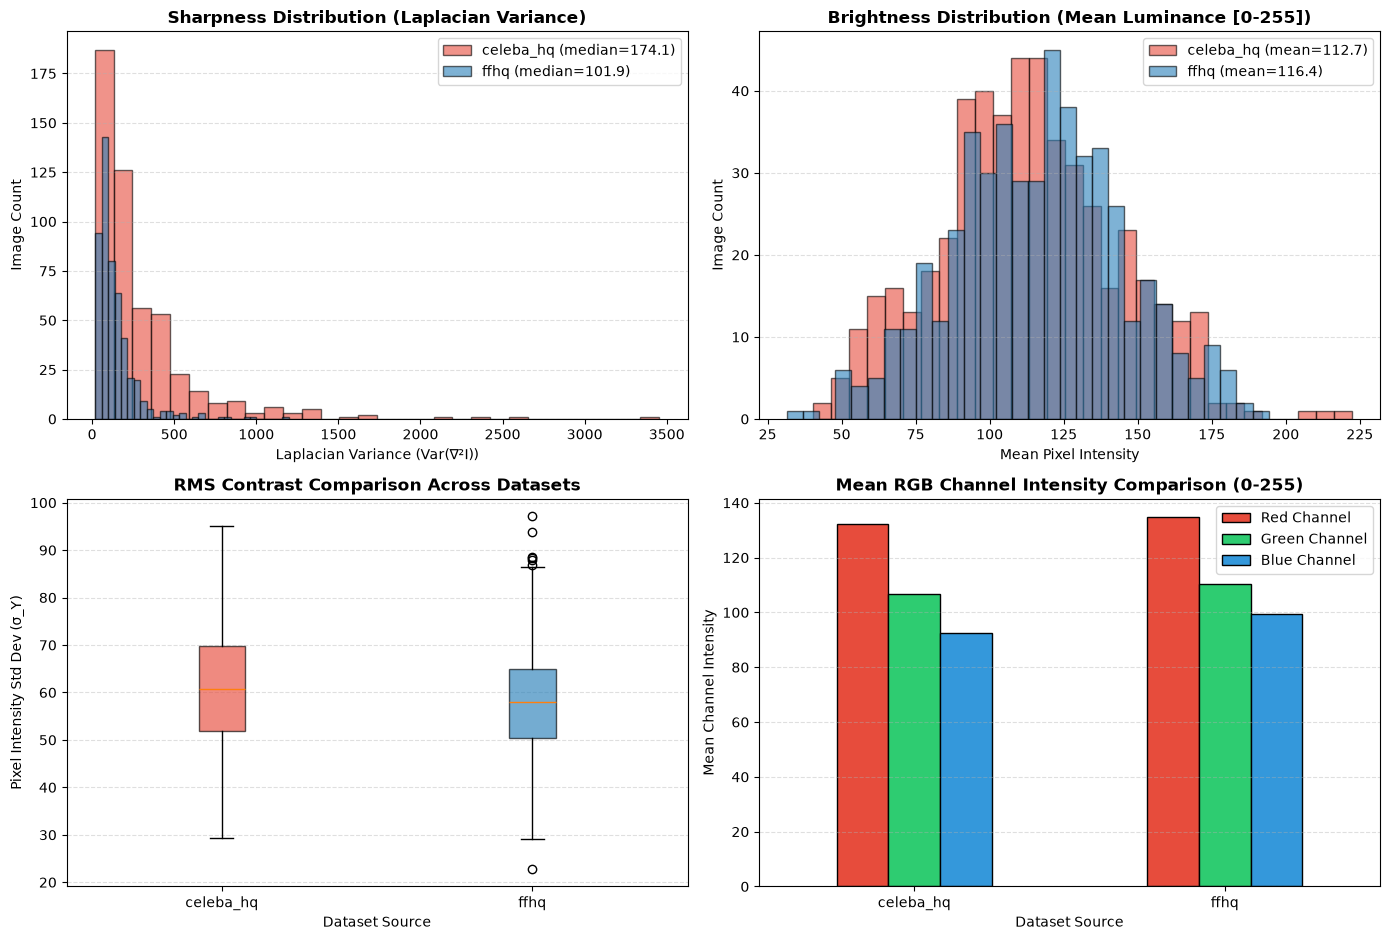

Computing MD5 & Perceptual Hashes: 100%|██████████| 500/500 [00:14<00:00, 35.35it/s]


Exact Duplicates (MD5): 2 | Perceptual Duplicates (dHash): 872


In [4]:
qual_results = analyze_image_quality(df_manifest, max_samples_per_group=500, random_state=42)
qual_per_img = qual_results["per_image"]
qual_summary_df = qual_results["summary"]

print("=== BẢNG TỔNG HỢP CHẤT LƯỢNG QUANG HỌC & MÀU SẮC ===")
display(qual_summary_df)

fig_qual = plot_image_quality(qual_per_img)
plt.show()

# Kiểm tra trùng lặp trên tập mẫu
dups_dict = detect_duplicate_images(df_manifest, max_samples=500, random_state=42, threshold=10)
print(f"Exact Duplicates (MD5): {len(dups_dict['exact_duplicates'])} | Perceptual Duplicates (dHash): {len(dups_dict['perceptual_duplicates'])}")

---
## Module 4: Visual Image Exploration (Representative Galleries)
Quan sát trực tiếp các mẫu ảnh đại diện từ FFHQ và CelebA-HQ với `random_state=42` kèm nhãn nhân khẩu học gốc từ metadata.

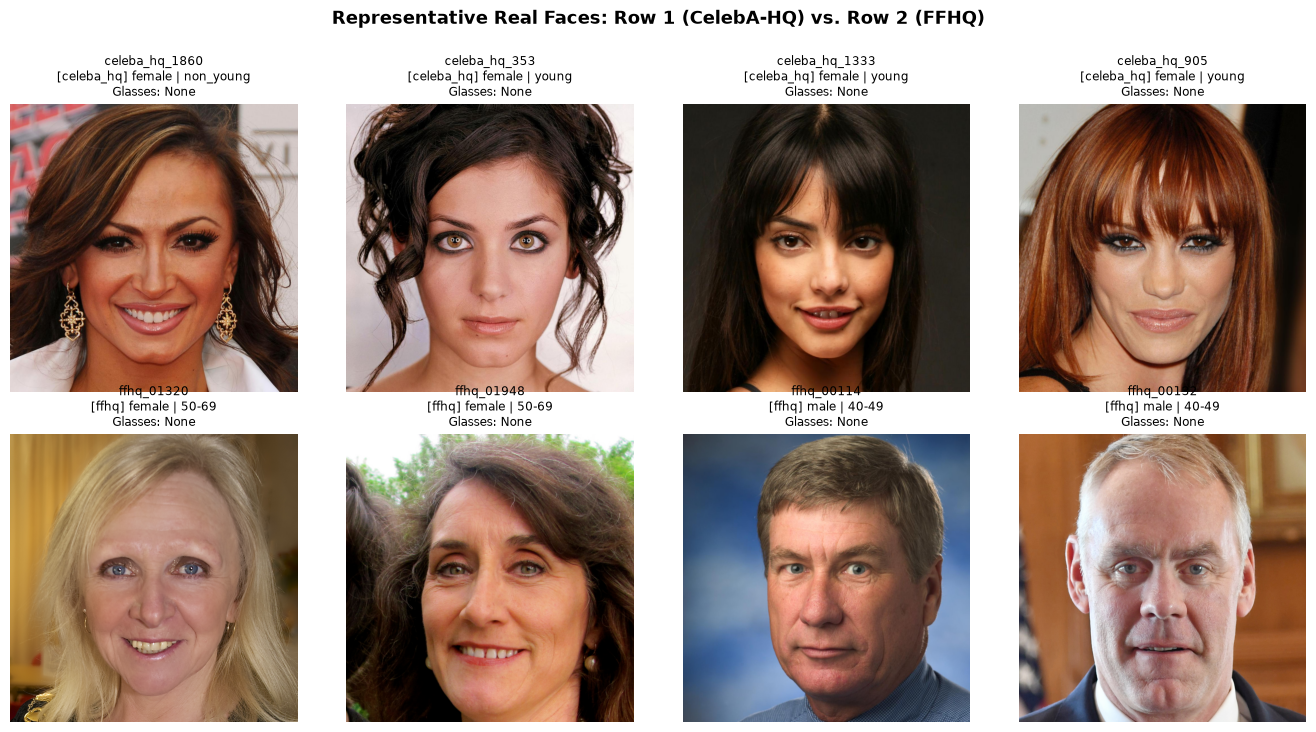

In [5]:
fig_gallery = display_image_gallery(
    df_manifest,
    n_per_group=4,
    random_state=42,
    title="Representative Real Faces: Row 1 (CelebA-HQ) vs. Row 2 (FFHQ)",
)
plt.show()

---
## Module 6: Demographics & Facial Attribute Analysis
Phân tích Giới tính (`gender_norm`), Phụ kiện kính mắt (`glasses_norm`), Nhóm tuổi chi tiết của FFHQ (`age_group_raw`), Nhóm tuổi chuẩn hóa (`young_norm`), Góc nghiêng đầu (`yaw, pitch, roll`) và Danh tính (`identity_id`).

=== 1. PHÂN BỐ GIỚI TÍNH CHUẨN HÓA ===


,dataset,gender_norm,count,percentage
0,celeba_hq,female,1547,77.35
1,celeba_hq,male,453,22.65
2,ffhq,female,592,50.68
3,ffhq,male,576,49.32


=== 2. PHÂN BỐ KÍNH MẮT / CHE KHUẤT VÙNG MẮT ===


,dataset,glasses_norm,count,percentage
0,celeba_hq,without_glasses,1940,97.00
1,celeba_hq,with_glasses,60,3.00
2,ffhq,without_glasses,912,78.08
3,ffhq,with_glasses,256,21.92


=== 3. THỐNG KÊ DANH TÍNH (IDENTITY UNIQUENESS) ===


,dataset,total_images,unique_identities,avg_images_per_identity,max_images_single_identity
0,celeba_hq,2000,1169,1.71,13
1,ffhq,1168,1168,1.00,1


=== 4. THỐNG KÊ GÓC QUAY ĐẦU 3D (FFHQ HEAD POSE) ===


,dataset,angle,count,mean_deg,std_deg,min_deg,median_deg,max_deg,extreme_pose_gt15_pct
0,ffhq,yaw,1168,3.84,16.71,-75.84,3.38,80.24,33.05
1,ffhq,pitch,1168,3.47,7.82,-33.93,3.83,27.90,8.13
2,ffhq,roll,1168,-0.01,3.59,-17.75,-0.13,33.46,0.43


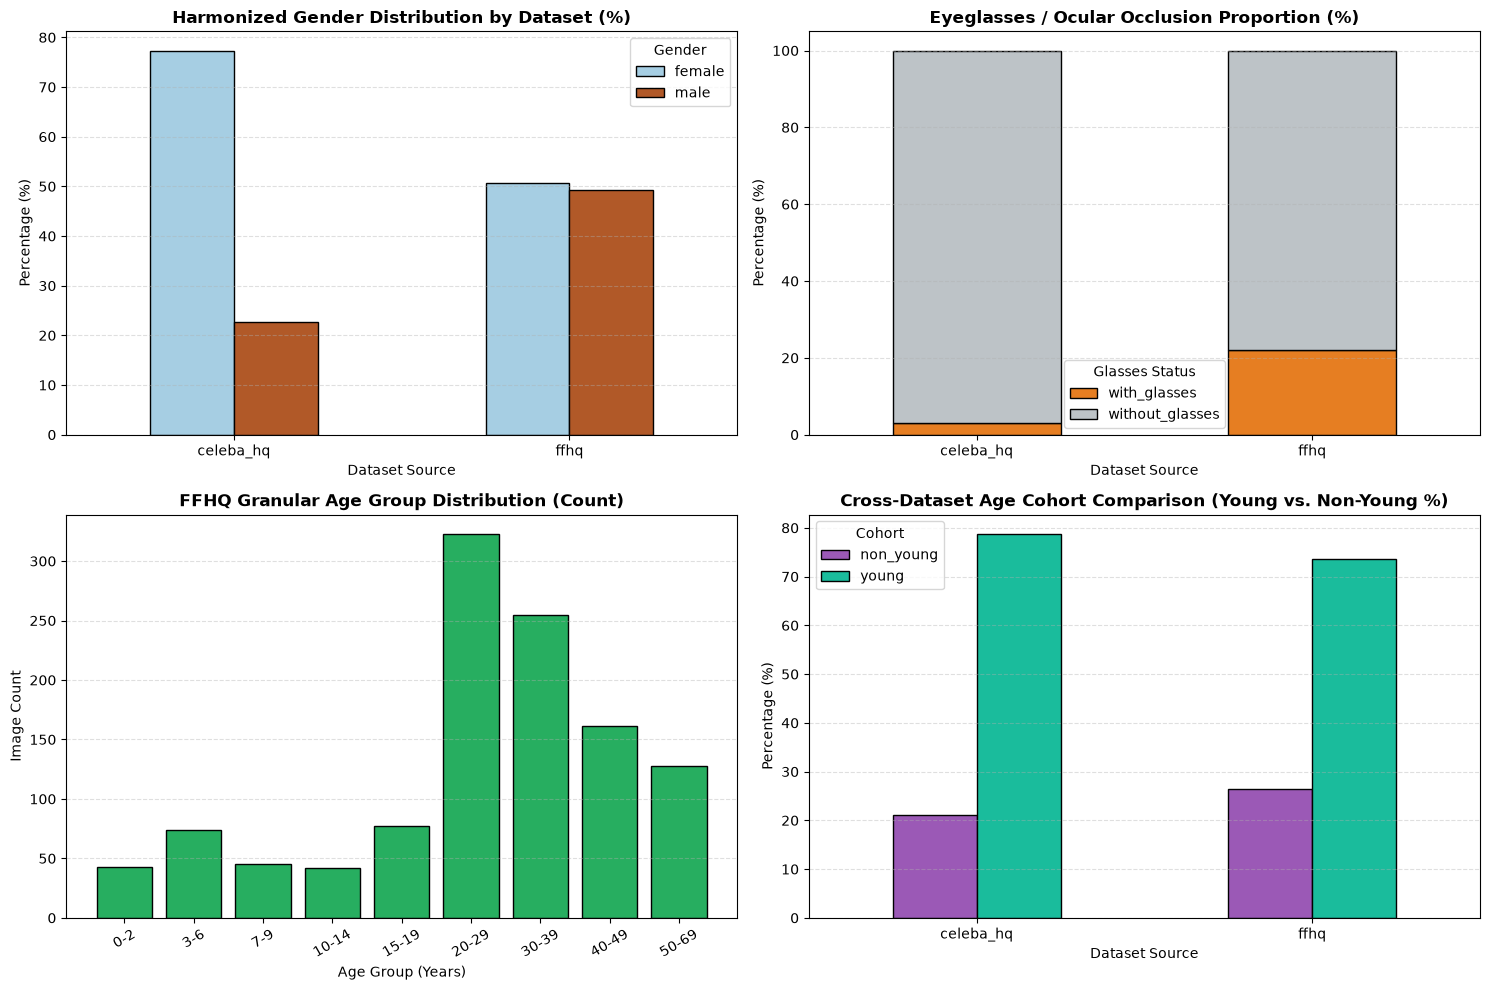

In [6]:
demo_results = analyze_demographics(df_manifest, only_existing=True)

print("=== 1. PHÂN BỐ GIỚI TÍNH CHUẨN HÓA ===")
display(demo_results["gender"])

print("=== 2. PHÂN BỐ KÍNH MẮT / CHE KHUẤT VÙNG MẮT ===")
display(demo_results["glasses_harmonized"])

print("=== 3. THỐNG KÊ DANH TÍNH (IDENTITY UNIQUENESS) ===")
display(demo_results["identity_summary"])

if not demo_results["head_pose"].empty:
    print("=== 4. THỐNG KÊ GÓC QUAY ĐẦU 3D (FFHQ HEAD POSE) ===")
    display(demo_results["head_pose"])

fig_demo = plot_demographics(demo_results)
plt.show()

---
## Module 7: Cross-Dataset Bias, Comparative Analysis & Artifact Export
So sánh đa chiều giữa FFHQ và CelebA-HQ, đánh giá nguy cơ *Domain Shift / Shortcut Learning* và xuất toàn bộ bảng biểu + báo cáo sang `experiments/eda/`.

=== BẢNG ĐỐI CHIẾU TỔNG HỢP FFHQ VS. CELEBA-HQ ===


,group,available_images,female_pct,male_pct,young_pct,with_glasses_pct,dominant_resolution,mean_aspect_ratio,mean_sharpness,mean_brightness,mean_contrast,rgb_mean_tuple
0,celeba_hq,2000,77.35,22.65,78.80,3.00,1024x1024,1.0,291.04,112.7,60.81,"(132.4, 106.6, 92.4)"
1,ffhq,1168,50.68,49.32,73.54,21.92,1024x1024,1.0,143.27,116.4,58.16,"(134.7, 110.4, 99.5)"


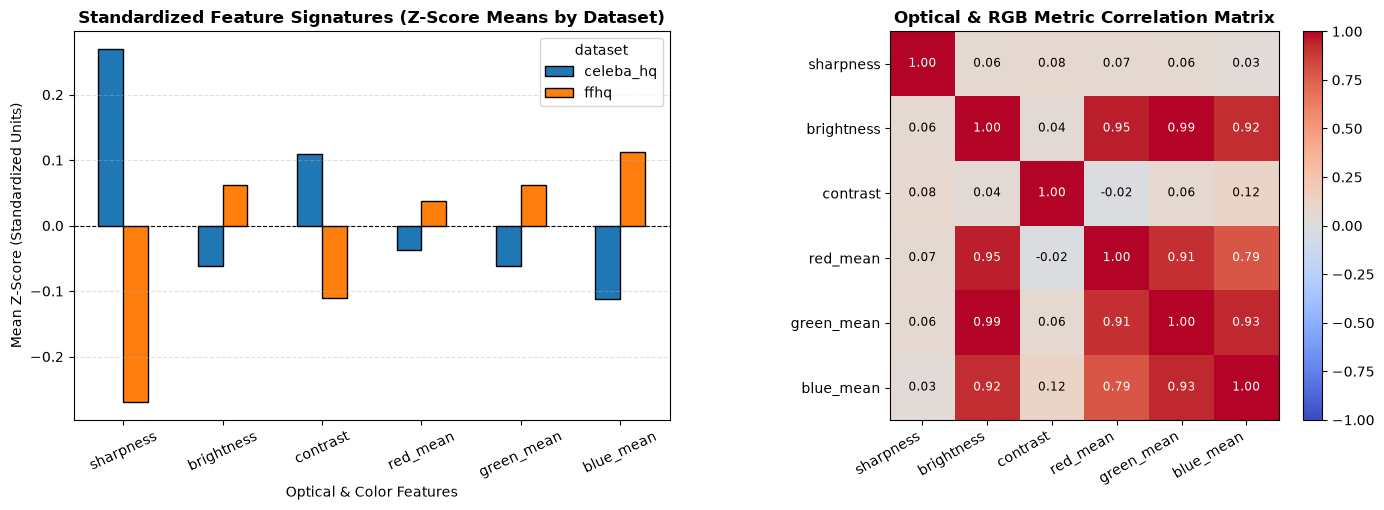

[2026-11-09 18:57:11] [INFO] [src.analysis.eda]: Exported 23 EDA artifacts to D:\CVIP\uth-cv-coursework\experiments\eda
Đã xuất thành công 23 tệp báo cáo, bảng CSV và biểu đồ vào: D:\CVIP\uth-cv-coursework\experiments\eda


In [7]:
comp_df = compare_datasets(df_manifest, dim_df=dim_df, quality_df=qual_per_img)
print("=== BẢNG ĐỐI CHIẾU TỔNG HỢP FFHQ VS. CELEBA-HQ ===")
display(comp_df)

fig_comp = plot_dataset_comparison(qual_per_img)
plt.show()

# Xuất toàn bộ kết quả ra experiments/eda/
report_md = generate_eda_summary(
    summary_df=summary_df,
    demo_results=demo_results,
    res_df=res_df,
    quality_summary_df=qual_summary_df,
    comparison_df=comp_df,
    duplicates_dict=dups_dict,
)

exported_files = export_eda_results(
    output_dir=OUTPUT_DIR,
    tables={
        "dataset_summary": summary_df,
        "dataset_size_comparison": size_comp_df,
        "resolution_summary": res_df,
        "aspect_ratio_summary": ar_df,
        "image_quality_summary": qual_summary_df,
        "cross_dataset_comparison": comp_df,
        **{f"demo_{k}": v for k, v in demo_results.items()},
    },
    figures={
        "01_dataset_distribution": fig_dist,
        "02_demographics_panel": fig_demo,
        "03_image_properties": fig_props,
        "04_image_quality_panel": fig_qual,
        "05_dataset_comparison_bias": fig_comp,
        "06_representative_gallery": fig_gallery,
    },
    report_markdown=report_md,
    quality_audit_tables={
        "image_quality_per_sample": qual_per_img,
        "exact_duplicates": dups_dict["exact_duplicates"],
        "perceptual_duplicates": dups_dict["perceptual_duplicates"],
    },
)
print(f"Đã xuất thành công {len(exported_files)} tệp báo cáo, bảng CSV và biểu đồ vào: {OUTPUT_DIR}")